# Sales Data Analysis and Business Insights Using Python

## Minor Project – Data Science Domain

**Project Title:** Sales Data Analysis and Business Insights Using Python  
**Domain:** Data Science  
**Organization:** Topgrade Innovation

### Objective

The objective of this project is to perform Exploratory Data Analysis (EDA)
on a sales dataset to identify sales trends, product performance,
revenue patterns, and meaningful business insights.

### Technologies Used

- Python
- Jupyter Notebook
- Pandas
- NumPy
- Matplotlib
- Seaborn

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Set visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Loading the Dataset

In [2]:
# Load the raw sales dataset

file_path = "../data/raw/sales_dataset.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
# Display the first five rows

df.head()

,Date,Product,Quantity,Revenue
0,2025-04-13,Mouse,11.00,"23,023.95"
1,2025-03-13,Laptop,2.00,"153,946.34"
2,2025-08-03,Laptop,5.00,"330,808.36"
3,2025-04-10,Mouse,3.00,"2,357.20"
4,2025-05-30,Headphones,8.00,"11,766.20"


In [4]:
df.head()

,Date,Product,Quantity,Revenue
0,2025-04-13,Mouse,11.00,"23,023.95"
1,2025-03-13,Laptop,2.00,"153,946.34"
2,2025-08-03,Laptop,5.00,"330,808.36"
3,2025-04-10,Mouse,3.00,"2,357.20"
4,2025-05-30,Headphones,8.00,"11,766.20"


## 2. Understanding the Dataset

In [5]:
# Number of rows and columns

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 302
Number of columns: 4


In [6]:
# Display column names

print("Column Names:")
print(df.columns.tolist())

Column Names:
['Date', 'Product', 'Quantity', 'Revenue']


In [7]:
# Check data types

df.dtypes

Date            str
Product         str
Quantity    float64
Revenue     float64
dtype: object

In [8]:
# Get complete dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 302 entries, 0 to 301
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Date      302 non-null    str    
 1   Product   301 non-null    str    
 2   Quantity  301 non-null    float64
 3   Revenue   301 non-null    float64
dtypes: float64(2), str(2)
memory usage: 14.8 KB


In [9]:
# Display the first 10 records

df.head(10)

,Date,Product,Quantity,Revenue
0,2025-04-13,Mouse,11.00,"23,023.95"
1,2025-03-13,Laptop,2.00,"153,946.34"
2,2025-08-03,Laptop,5.00,"330,808.36"
3,2025-04-10,Mouse,3.00,"2,357.20"
4,2025-05-30,Headphones,8.00,"11,766.20"
5,2025-10-21,Smartphone,4.00,"72,084.11"
6,2025-10-04,Smartphone,2.00,"69,344.00"
7,2025-01-22,Smartphone,NaN,"18,190.79"
8,2025-02-18,Mouse,10.00,"15,495.49"
9,2025-07-07,Laptop,3.00,"216,981.71"


In [10]:
# Display the last 5 records

df.tail()

,Date,Product,Quantity,Revenue
297,2025-09-18,Headphones,12.00,"18,050.40"
298,2025-01-13,Keyboard,4.00,"10,593.37"
299,2025-11-17,Smartphone,1.00,"21,748.27"
300,2025-12-30,Mouse,9.00,"13,756.22"
301,2025-02-10,Smartphone,5.00,"129,996.92"


## 3. Checking Missing Values

In [11]:
# Check the number of missing values in each column

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
Date        0
Product     1
Quantity    1
Revenue     1
dtype: int64


In [12]:
# Calculate percentage of missing values

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": missing_percentage
})

missing_report

,Missing Values,Percentage
Date,0,0.00
Product,1,0.33
Quantity,1,0.33
Revenue,1,0.33


### Checking Duplicate Records

In [13]:
# Check for duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 2


In [14]:
# Check the data types of all columns

print("Data types:")
print(df.dtypes)

Data types:
Date            str
Product         str
Quantity    float64
Revenue     float64
dtype: object


### Basic Statistical Summary

In [15]:
# Generate statistical summary

df.describe()

,Quantity,Revenue
count,301.00,301.00
mean,5.31,"81,200.84"
std,3.68,"98,096.44"
min,1.00,899.42
25%,2.00,"12,883.39"
50%,4.00,"36,920.97"
75%,8.00,"116,531.00"
max,14.00,"411,236.37"


In [16]:
missing_report

,Missing Values,Percentage
Date,0,0.00
Product,1,0.33
Quantity,1,0.33
Revenue,1,0.33


## 4. Data Cleaning

### 4.1 Converting Data Types

In [17]:
# Convert Date column to datetime format

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Date column converted successfully.")
print(df.dtypes)

Date column converted successfully.
Date        datetime64[us]
Product                str
Quantity           float64
Revenue            float64
dtype: object


In [18]:
# Convert Quantity and Revenue to numeric values

df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["Revenue"] = pd.to_numeric(df["Revenue"], errors="coerce")

print("Numerical columns converted successfully.")
print(df.dtypes)

Numerical columns converted successfully.
Date        datetime64[us]
Product                str
Quantity           float64
Revenue            float64
dtype: object


### 4.2 Handling Missing Values

In [19]:
# Fill missing Product values with the most frequent product

if df["Product"].isnull().sum() > 0:
    df["Product"] = df["Product"].fillna(df["Product"].mode()[0])

print("Missing Product values handled.")

Missing Product values handled.


In [20]:
# Fill missing Quantity values using the median

if df["Quantity"].isnull().sum() > 0:
    df["Quantity"] = df["Quantity"].fillna(df["Quantity"].median())

print("Missing Quantity values handled.")

Missing Quantity values handled.


In [21]:
# Fill missing Revenue values using the median

if df["Revenue"].isnull().sum() > 0:
    df["Revenue"] = df["Revenue"].fillna(df["Revenue"].median())

print("Missing Revenue values handled.")

Missing Revenue values handled.


In [22]:
# Check duplicate records

print("Duplicate rows before removal:", df.duplicated().sum())

Duplicate rows before removal: 2


In [23]:
# Remove duplicate rows

df = df.drop_duplicates().reset_index(drop=True)

print("Duplicate rows after removal:", df.duplicated().sum())

Duplicate rows after removal: 0


In [24]:
# Check for invalid/missing dates

print("Invalid or missing dates:", df["Date"].isnull().sum())

Invalid or missing dates: 0


In [25]:
# Remove rows with invalid dates

df = df.dropna(subset=["Date"]).reset_index(drop=True)

print("Invalid date records removed.")

Invalid date records removed.


In [26]:
# Verify the cleaned dataset

print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows after cleaning:")
print(df.duplicated().sum())

print("\nDataset shape after cleaning:")
print(df.shape)

Missing values after cleaning:
Date        0
Product     0
Quantity    0
Revenue     0
dtype: int64

Duplicate rows after cleaning:
0

Dataset shape after cleaning:
(300, 4)


In [27]:
# Display the cleaned dataset

df.head(10)

,Date,Product,Quantity,Revenue
0,2025-04-13,Mouse,11.00,"23,023.95"
1,2025-03-13,Laptop,2.00,"153,946.34"
2,2025-08-03,Laptop,5.00,"330,808.36"
3,2025-04-10,Mouse,3.00,"2,357.20"
4,2025-05-30,Headphones,8.00,"11,766.20"
5,2025-10-21,Smartphone,4.00,"72,084.11"
6,2025-10-04,Smartphone,2.00,"69,344.00"
7,2025-01-22,Smartphone,4.00,"18,190.79"
8,2025-02-18,Mouse,10.00,"15,495.49"
9,2025-07-07,Laptop,3.00,"216,981.71"


In [28]:
# Save cleaned dataset

cleaned_file_path = "../data/cleaned/cleaned_sales_dataset.csv"

df.to_csv(cleaned_file_path, index=False)

print("Cleaned dataset saved successfully!")
print(cleaned_file_path)

Cleaned dataset saved successfully!
../data/cleaned/cleaned_sales_dataset.csv


## 5. Sales Analysis

### 5.1 Overall Sales Statistics

In [29]:
# Calculate total revenue

total_revenue = df["Revenue"].sum()

print(f"Total Revenue: ₹{total_revenue:,.2f}")

Total Revenue: ₹24,334,620.58


In [30]:
# Calculate average revenue per transaction

average_revenue = df["Revenue"].mean()

print(f"Average Revenue per Transaction: ₹{average_revenue:,.2f}")

Average Revenue per Transaction: ₹81,115.40


In [31]:
# Calculate total quantity sold

total_quantity = df["Quantity"].sum()

print(f"Total Quantity Sold: {total_quantity:,.0f} units")

Total Quantity Sold: 1,587 units


In [32]:
# Calculate average quantity per transaction

average_quantity = df["Quantity"].mean()

print(f"Average Quantity per Transaction: {average_quantity:.2f} units")

Average Quantity per Transaction: 5.29 units


### 5.2 Overall Sales Summary

In [33]:
# Create overall sales summary

sales_summary = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Average Revenue per Transaction",
        "Total Quantity Sold",
        "Average Quantity per Transaction"
    ],
    "Value": [
        total_revenue,
        average_revenue,
        total_quantity,
        average_quantity
    ]
})

sales_summary

,Metric,Value
0,Total Revenue,"24,334,620.58"
1,Average Revenue per Transaction,"81,115.40"
2,Total Quantity Sold,"1,587.00"
3,Average Quantity per Transaction,5.29


### 5.3 Product-Wise Sales Analysis

In [34]:
# Calculate product-wise sales performance

product_summary = (
    df.groupby("Product")
      .agg(
          Total_Quantity=("Quantity", "sum"),
          Total_Revenue=("Revenue", "sum"),
          Average_Revenue=("Revenue", "mean")
      )
      .sort_values("Total_Revenue", ascending=False)
)

product_summary

,Total_Quantity,Total_Revenue,Average_Revenue
Product,,,
Laptop,163.00,"12,164,760.73","225,273.35"
Smartphone,232.00,"6,885,490.38","118,715.35"
Monitor,144.00,"2,805,942.35","58,457.13"
Headphones,324.00,"1,186,341.37","28,246.22"
Keyboard,319.00,"684,741.73","15,924.23"
Mouse,405.00,"607,344.02","11,042.62"


In [35]:
# Identify the product generating the highest revenue

best_revenue_product = product_summary["Total_Revenue"].idxmax()
best_revenue_value = product_summary["Total_Revenue"].max()

print("Highest Revenue Product:", best_revenue_product)
print(f"Revenue Generated: ₹{best_revenue_value:,.2f}")

Highest Revenue Product: Laptop
Revenue Generated: ₹12,164,760.73


In [36]:
# Identify the product with the highest quantity sold

best_quantity_product = product_summary["Total_Quantity"].idxmax()
best_quantity_value = product_summary["Total_Quantity"].max()

print("Highest Quantity Product:", best_quantity_product)
print(f"Quantity Sold: {best_quantity_value:,.0f} units")

Highest Quantity Product: Mouse
Quantity Sold: 405 units


In [37]:
# Identify the product generating the lowest revenue

lowest_revenue_product = product_summary["Total_Revenue"].idxmin()
lowest_revenue_value = product_summary["Total_Revenue"].min()

print("Lowest Revenue Product:", lowest_revenue_product)
print(f"Revenue Generated: ₹{lowest_revenue_value:,.2f}")

Lowest Revenue Product: Mouse
Revenue Generated: ₹607,344.02


In [38]:
# Save product-wise analysis results

product_summary.to_csv("../outputs/results/product_sales_summary.csv")

print("Product sales summary saved successfully!")

Product sales summary saved successfully!


In [39]:
# Display product-wise revenue ranking

product_summary[["Total_Revenue", "Total_Quantity"]]

,Total_Revenue,Total_Quantity
Product,,
Laptop,"12,164,760.73",163.00
Smartphone,"6,885,490.38",232.00
Monitor,"2,805,942.35",144.00
Headphones,"1,186,341.37",324.00
Keyboard,"684,741.73",319.00
Mouse,"607,344.02",405.00


## 6. Data Visualization

### 6.1 Bar Chart – Revenue by Product

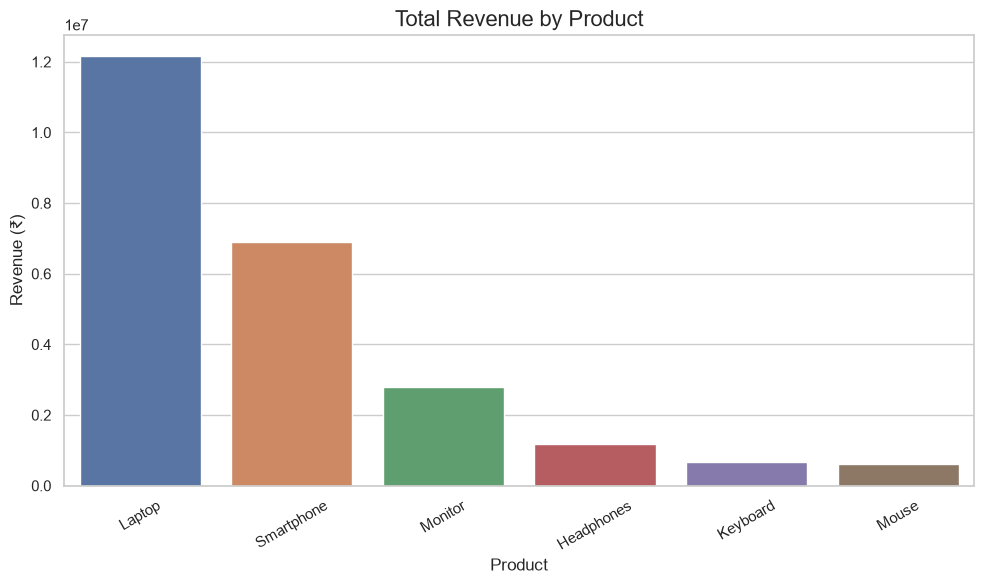

In [40]:
# Bar chart showing total revenue by product

plt.figure(figsize=(10, 6))

sns.barplot(
    data=product_summary.reset_index(),
    x="Product",
    y="Total_Revenue",
    hue="Product",
    legend=False
)

plt.title("Total Revenue by Product", fontsize=16)
plt.xlabel("Product")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=30)

plt.tight_layout()

# Save the chart
plt.savefig("../outputs/graphs/revenue_by_product.png", dpi=300)

plt.show()

### 6.2 Line Chart – Monthly Revenue Trend

In [41]:
# Create monthly revenue data

df["Month"] = df["Date"].dt.to_period("M").astype(str)

monthly_sales = df.groupby("Month")["Revenue"].sum()

monthly_sales

Month
2025-01   1,752,372.24
2025-02   2,350,101.54
2025-03   2,988,699.78
2025-04   1,774,877.96
2025-05   3,511,756.91
2025-06   1,633,463.19
2025-07   1,631,620.82
2025-08   2,057,084.32
2025-09   2,024,972.99
2025-10   2,449,298.09
2025-11   1,009,732.88
2025-12   1,150,639.86
Name: Revenue, dtype: float64

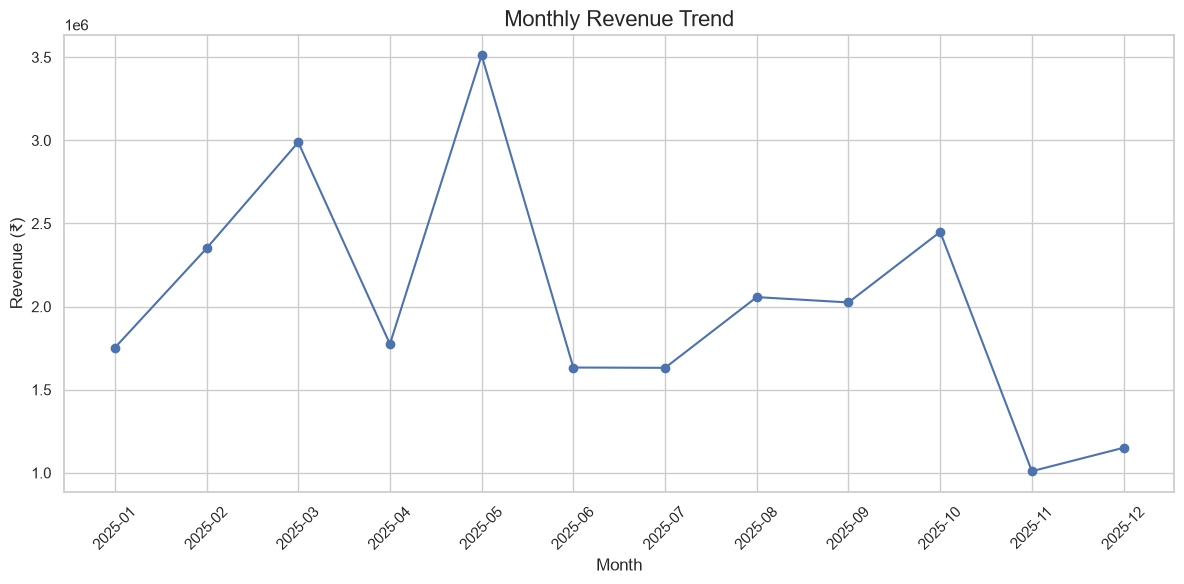

In [42]:
# Line chart showing monthly revenue trend

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Revenue Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")

plt.xticks(rotation=45)

plt.tight_layout()

# Save the chart
plt.savefig("../outputs/graphs/monthly_sales_trend.png", dpi=300)

plt.show()

### 6.3 Pie Chart – Revenue Share by Product

In [43]:
# Calculate total revenue by product

revenue_by_product = df.groupby("Product")["Revenue"].sum()

revenue_by_product

Product
Headphones    1,186,341.37
Keyboard        684,741.73
Laptop       12,164,760.73
Monitor       2,805,942.35
Mouse           607,344.02
Smartphone    6,885,490.38
Name: Revenue, dtype: float64

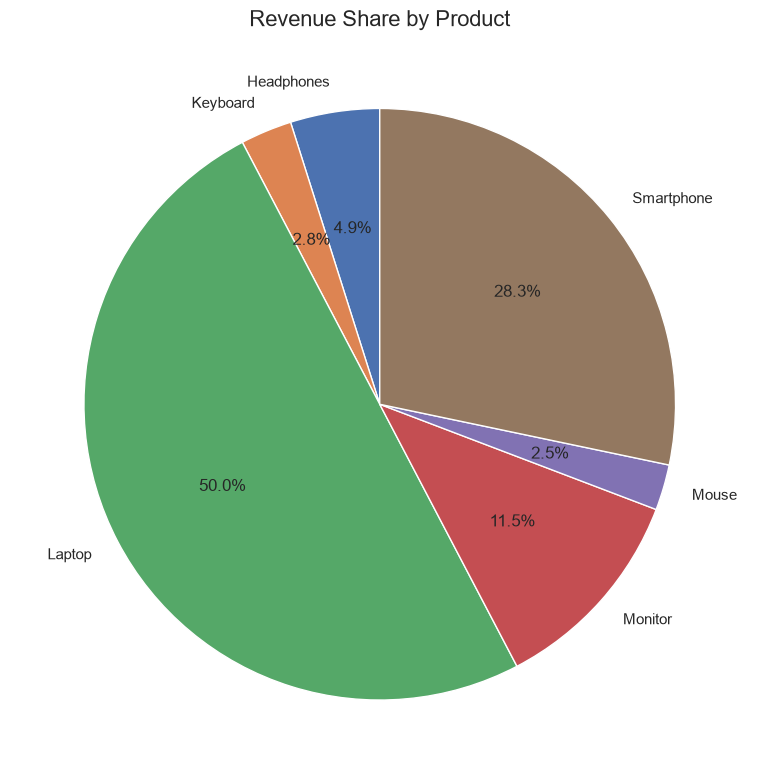

In [44]:
# Pie chart showing revenue share by product

plt.figure(figsize=(8, 8))

plt.pie(
    revenue_by_product.values,
    labels=revenue_by_product.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Share by Product", fontsize=16)

plt.tight_layout()

# Save the chart
plt.savefig("../outputs/graphs/revenue_share.png", dpi=300)

plt.show()

### 6.4 Bar Chart – Quantity Sold by Product

In [45]:
# Calculate quantity sold by product

quantity_by_product = (
    df.groupby("Product")["Quantity"]
      .sum()
      .sort_values(ascending=False)
)

quantity_by_product

Product
Mouse        405.00
Headphones   324.00
Keyboard     319.00
Smartphone   232.00
Laptop       163.00
Monitor      144.00
Name: Quantity, dtype: float64

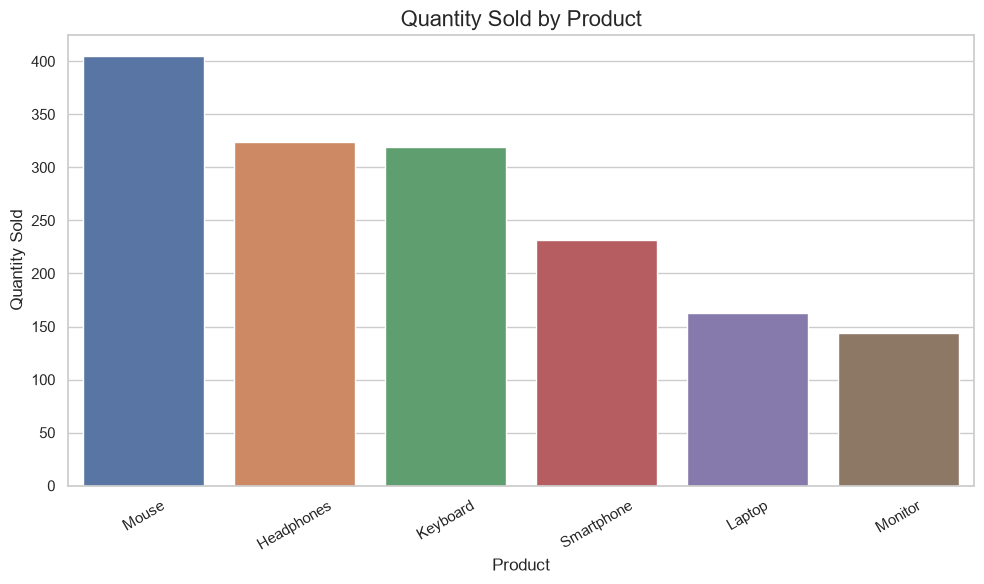

In [46]:
# Bar chart showing quantity sold by product

plt.figure(figsize=(10, 6))

sns.barplot(
    x=quantity_by_product.index,
    y=quantity_by_product.values,
    hue=quantity_by_product.index,
    legend=False
)

plt.title("Quantity Sold by Product", fontsize=16)
plt.xlabel("Product")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig("../outputs/graphs/quantity_by_product.png", dpi=300)

plt.show()

## 7. Business Insights and Observations

### 7.1 Monthly Sales Analysis

In [47]:
# Identify highest and lowest revenue months

highest_month = monthly_sales.idxmax()
highest_month_revenue = monthly_sales.max()

lowest_month = monthly_sales.idxmin()
lowest_month_revenue = monthly_sales.min()

print("Highest Revenue Month:")
print(f"{highest_month} - ₹{highest_month_revenue:,.2f}")

print("\nLowest Revenue Month:")
print(f"{lowest_month} - ₹{lowest_month_revenue:,.2f}")

Highest Revenue Month:
2025-05 - ₹3,511,756.91

Lowest Revenue Month:
2025-11 - ₹1,009,732.88


In [48]:
# Calculate revenue percentage for each product

product_summary["Revenue_Percentage"] = (
    product_summary["Total_Revenue"] / total_revenue
) * 100

product_summary

,Total_Quantity,Total_Revenue,Average_Revenue,Revenue_Percentage
Product,,,,
Laptop,163.00,"12,164,760.73","225,273.35",49.99
Smartphone,232.00,"6,885,490.38","118,715.35",28.30
Monitor,144.00,"2,805,942.35","58,457.13",11.53
Headphones,324.00,"1,186,341.37","28,246.22",4.88
Keyboard,319.00,"684,741.73","15,924.23",2.81
Mouse,405.00,"607,344.02","11,042.62",2.50


In [49]:
# Find the top 3 products by revenue

top_3_products = product_summary.sort_values(
    "Total_Revenue",
    ascending=False
).head(3)

top_3_products[["Total_Revenue", "Revenue_Percentage"]]

,Total_Revenue,Revenue_Percentage
Product,,
Laptop,"12,164,760.73",49.99
Smartphone,"6,885,490.38",28.30
Monitor,"2,805,942.35",11.53


In [50]:
# Calculate the difference between highest and lowest monthly revenue

monthly_revenue_difference = highest_month_revenue - lowest_month_revenue

print(
    f"Difference between highest and lowest monthly revenue: "
    f"₹{monthly_revenue_difference:,.2f}"
)

Difference between highest and lowest monthly revenue: ₹2,502,024.03


### 7.2 Key Business Insights

In [51]:
# Generate key business insights

print("=" * 75)
print("KEY BUSINESS INSIGHTS")
print("=" * 75)

print(
    f"\n1. Highest Revenue Product:"
    f"\n   {best_revenue_product} generated ₹{best_revenue_value:,.2f} "
    f"in total revenue."
)

print(
    f"\n2. Highest Quantity Sold:"
    f"\n   {best_quantity_product} recorded the highest sales volume "
    f"with {best_quantity_value:,.0f} units."
)

print(
    f"\n3. Lowest Revenue Product:"
    f"\n   {lowest_revenue_product} generated ₹{lowest_revenue_value:,.2f} "
    f"in total revenue."
)

print(
    f"\n4. Best Sales Month:"
    f"\n   {highest_month} recorded the highest monthly revenue "
    f"of ₹{highest_month_revenue:,.2f}."
)

print(
    f"\n5. Lowest Sales Month:"
    f"\n   {lowest_month} recorded the lowest monthly revenue "
    f"of ₹{lowest_month_revenue:,.2f}."
)

print(
    f"\n6. Overall Revenue:"
    f"\n   The business generated total revenue of ₹{total_revenue:,.2f}."
)

print(
    f"\n7. Average Transaction Revenue:"
    f"\n   The average revenue per transaction was "
    f"₹{average_revenue:,.2f}."
)

KEY BUSINESS INSIGHTS

1. Highest Revenue Product:
   Laptop generated ₹12,164,760.73 in total revenue.

2. Highest Quantity Sold:
   Mouse recorded the highest sales volume with 405 units.

3. Lowest Revenue Product:
   Mouse generated ₹607,344.02 in total revenue.

4. Best Sales Month:
   2025-05 recorded the highest monthly revenue of ₹3,511,756.91.

5. Lowest Sales Month:
   2025-11 recorded the lowest monthly revenue of ₹1,009,732.88.

6. Overall Revenue:
   The business generated total revenue of ₹24,334,620.58.

7. Average Transaction Revenue:
   The average revenue per transaction was ₹81,115.40.


### Key Observations

**1. Product Performance**

The product-wise analysis shows that the highest-revenue product contributes significantly to the overall sales revenue. This indicates that the product has strong revenue-generating potential and should receive appropriate inventory and marketing attention.

**2. Sales Volume**

The product with the highest quantity sold indicates strong customer demand. Monitoring the inventory of this product can help prevent stock shortages.

**3. Monthly Sales Trend**

The monthly revenue line chart shows variations in sales throughout the year. The highest-sales month represents a period of strong business performance, while the lowest-sales month may require further investigation.

**4. Revenue Distribution**

The pie chart shows the percentage contribution of each product to total revenue. Products with larger revenue shares have a greater impact on overall business performance.

**5. Business Decision Making**

The analysis can help management make better decisions regarding inventory planning, product promotion, marketing strategies, and sales forecasting.

### 7.3 Correlation Between Quantity and Revenue

In [52]:
# Calculate correlation between Quantity and Revenue

correlation = df[["Quantity", "Revenue"]].corr()

correlation

,Quantity,Revenue
Quantity,1.00,-0.12
Revenue,-0.12,1.00


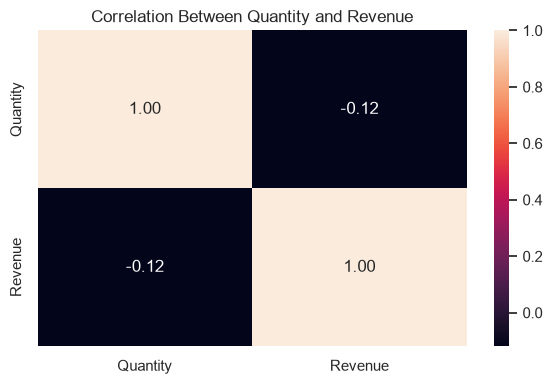

In [53]:
# Visualize correlation

plt.figure(figsize=(6, 4))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Between Quantity and Revenue")

plt.tight_layout()

plt.savefig("../outputs/graphs/correlation_heatmap.png", dpi=300)

plt.show()

In [54]:
# Save business insights to a text file

insights = f"""
SALES DATA ANALYSIS - BUSINESS INSIGHTS

1. Highest Revenue Product:
{best_revenue_product} - ₹{best_revenue_value:,.2f}

2. Highest Quantity Sold:
{best_quantity_product} - {best_quantity_value:,.0f} units

3. Lowest Revenue Product:
{lowest_revenue_product} - ₹{lowest_revenue_value:,.2f}

4. Highest Revenue Month:
{highest_month} - ₹{highest_month_revenue:,.2f}

5. Lowest Revenue Month:
{lowest_month} - ₹{lowest_month_revenue:,.2f}

6. Total Revenue:
₹{total_revenue:,.2f}

7. Average Revenue per Transaction:
₹{average_revenue:,.2f}

8. Total Quantity Sold:
{total_quantity:,.0f} units

The analysis shows differences in product performance and monthly
revenue patterns. These findings can support inventory planning,
product promotion, and sales strategy.
"""

with open("../outputs/results/business_insights.txt", "w", encoding="utf-8") as file:
    file.write(insights)

print("Business insights saved successfully!")

Business insights saved successfully!


## 8. Conclusion

The Exploratory Data Analysis performed on the sales dataset provided meaningful insights into product performance, sales volume, revenue distribution, and monthly sales trends.

The dataset was first inspected and cleaned by handling missing values, converting data types, and removing duplicate records. Statistical analysis was then performed to calculate total revenue, average revenue, total quantity sold, and product-wise performance.

The visualizations helped identify differences in product revenue, revenue contribution, and monthly sales patterns. The analysis also identified the highest- and lowest-performing products and months.

These insights can support business decisions related to inventory management, product promotion, marketing strategy, and sales planning.

Overall, this project demonstrates how Python, Pandas, NumPy, Matplotlib, and Seaborn can be used to transform raw sales data into meaningful business insights through Exploratory Data Analysis.

## 9. Project Summary

### Dataset
The dataset contains sales transaction information with the following fields:

- **Date** – Transaction date
- **Product** – Product name
- **Quantity** – Number of units sold
- **Revenue** – Revenue generated

### Data Processing
- Checked missing values
- Checked duplicate records
- Converted Date to datetime format
- Converted numerical columns to numeric format
- Handled missing values
- Removed duplicate records
- Saved the cleaned dataset

### Analysis Performed
- Total revenue calculation
- Average revenue calculation
- Total quantity calculation
- Average quantity calculation
- Product-wise revenue analysis
- Product-wise quantity analysis
- Monthly revenue analysis
- Revenue contribution analysis
- Correlation analysis

### Visualizations
- Revenue by Product – Bar Chart
- Monthly Revenue Trend – Line Chart
- Revenue Share by Product – Pie Chart
- Quantity Sold by Product – Bar Chart
- Quantity and Revenue Correlation – Heatmap

## 10. Submission Screenshot Checklist

The following screenshots should be included in the final project documentation:

| No. | Screenshot | Status |
|---|---|---|
| 1 | Original Dataset | Completed |
| 2 | Missing Value Analysis | Completed |
| 3 | Cleaned Dataset | Completed |
| 4 | Product Analysis | Completed |
| 5 | Revenue by Product Bar Chart | Completed |
| 6 | Monthly Revenue Line Chart | Completed |
| 7 | Revenue Share Pie Chart | Completed |
| 8 | Business Insights | Completed |

In [55]:
# ==========================================
# FINAL PROJECT RESULTS
# ==========================================

print("=" * 70)
print("FINAL SALES ANALYSIS RESULTS")
print("=" * 70)

print(f"\nTotal Revenue: ₹{total_revenue:,.2f}")
print(f"Average Revenue per Transaction: ₹{average_revenue:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,.0f} units")
print(f"Average Quantity per Transaction: {average_quantity:.2f} units")

print(f"\nHighest Revenue Product: {best_revenue_product}")
print(f"Highest Product Revenue: ₹{best_revenue_value:,.2f}")

print(f"\nHighest Quantity Product: {best_quantity_product}")
print(f"Highest Quantity Sold: {best_quantity_value:,.0f} units")

print(f"\nLowest Revenue Product: {lowest_revenue_product}")
print(f"Lowest Product Revenue: ₹{lowest_revenue_value:,.2f}")

print(f"\nHighest Revenue Month: {highest_month}")
print(f"Highest Monthly Revenue: ₹{highest_month_revenue:,.2f}")

print(f"\nLowest Revenue Month: {lowest_month}")
print(f"Lowest Monthly Revenue: ₹{lowest_month_revenue:,.2f}")

print("\n" + "=" * 70)
print("PROJECT ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 70)

FINAL SALES ANALYSIS RESULTS

Total Revenue: ₹24,334,620.58
Average Revenue per Transaction: ₹81,115.40
Total Quantity Sold: 1,587 units
Average Quantity per Transaction: 5.29 units

Highest Revenue Product: Laptop
Highest Product Revenue: ₹12,164,760.73

Highest Quantity Product: Mouse
Highest Quantity Sold: 405 units

Lowest Revenue Product: Mouse
Lowest Product Revenue: ₹607,344.02

Highest Revenue Month: 2025-05
Highest Monthly Revenue: ₹3,511,756.91

Lowest Revenue Month: 2025-11
Lowest Monthly Revenue: ₹1,009,732.88

PROJECT ANALYSIS COMPLETED SUCCESSFULLY
